# Particle filtering

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from particle_filter import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights, esses = filter(stations, z, n=1000, T=10)

In [5]:
from metrics import record_esses
record_esses("results/particle_filter_esses.csv", "filtering_T10", esses)
esses

[tensor(1.),
 tensor(1.0120),
 tensor(1.),
 tensor(1.0000),
 tensor(1.0000),
 tensor(1.1186),
 tensor(1.),
 tensor(1.0296),
 tensor(1.1650),
 tensor(1.0000)]

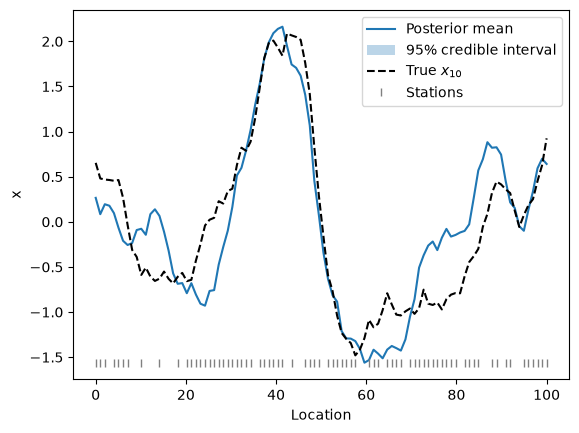

In [6]:
import numpy as np
from plots import *

t = 10
samples = torch.stack([p[1] for p in particles]).numpy() # (n, grid)
weights = log_weights.exp().numpy()
plot_state_band(samples, x[t].numpy(), t, stations, weights,
    save="figures/particle_filter_filtering_band.png")

In [7]:
from metrics import record_metrics
record_metrics("results/particle_filter.csv", "filtering_T10", samples, x[t].numpy(), weights)

{'experiment': 'filtering_T10',
 'rmspe': 0.4202370345592499,
 'mean_crps': 0.341248095035553}

## Particle filter no resampling
We run the particle filter with no resampling just to look at ESS values.

In [8]:
torch.manual_seed(548)
particles, log_weights, esses = filter(stations, z, n=1000, T=10, resample=False)
record_esses("results/particle_filter_esses.csv", "filtering_T10_no_resampling", esses)
esses

[tensor(1.),
 tensor(1.0005),
 tensor(1.),
 tensor(1.),
 tensor(1.0001),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.)]

## Single update at $T=10$

In [ ]:
torch.manual_seed(548)
particles, log_weights, esses = filter(stations, z[9:10], n=1000, T=1)
record_esses("results/particle_filter_esses.csv", "single_update_T10", esses)
esses

In [ ]:
samples = torch.stack([p[1] for p in particles]).numpy() # (n, grid)
weights = log_weights.exp().numpy()
plot_state_band(samples, x[t].numpy(), t, stations, weights,
                save="figures/particle_filter_single_update_band.png")

In [ ]:
record_metrics("results/particle_filter.csv", "single_update_T10", samples, x[t].numpy(), weights)